# Human Face Emotion Classification with Multi-Layer Perceptrons (MLP only)

**Student:** Adel Ahmed Fathi Amer  |  **ID:** 224100177

**Task.** Build a classifier that detects the emotion shown on a human face using the Kaggle dataset
[`samithsachidanandan/human-face-emotions`](https://www.kaggle.com/datasets/samithsachidanandan/human-face-emotions)
(5 classes: Angry, Fear, Happy, Sad, Surprise).

**Constraint.** Only MLPs (stacks of fully-connected layers) are allowed - no convolutional networks, no transformers,
no pre-trained networks. PyTorch is used purely as a fast (GPU) engine to train `nn.Linear` stacks, and scikit-learn's
`MLPClassifier` is used as a cross-check. Convolution-free hand-crafted features (HOG, LBP, PCA) are only used as *input
preprocessing* for the MLP.

**Protocol.** (1) load + clean data, (2) stratified train / validation / test split, (3) many experiments
on preprocessing, architecture, activation, regularisation, optimiser, class imbalance and augmentation - **all
selection decisions use the validation set only**, (4) the test set is touched exactly once, for the final model.

Model selection metric: **macro-F1** on the validation set (the classes are imbalanced, so plain accuracy would
favour the majority class *Happy*); accuracy is reported as well.

In [1]:
import os, sys, time, json, hashlib, random, warnings, tempfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from skimage.feature import hog, local_binary_pattern
from joblib import Parallel, delayed
from IPython.display import display
import kagglehub

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figs', exist_ok=True); os.makedirs('results', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
PAL = '#3b6ea5'
def savefig(name):
    plt.savefig(f'figs/{name}.png', dpi=140, bbox_inches='tight')
print('torch', torch.__version__, '| device:', dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


C:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data loading
The dataset is downloaded with `kagglehub`. Every image is converted to **48x48 grayscale** (almost all images in the
dataset already are 48x48 grayscale; the few large colour photos are resized with Lanczos filtering).

In [2]:
path = kagglehub.dataset_download('samithsachidanandan/human-face-emotions')
data_dir = None
for d, _, _ in os.walk(path):
    if os.path.basename(d) == 'Angry':
        data_dir = os.path.dirname(d); break
CLASSES = sorted(os.listdir(data_dir))                   # folder names (the dataset spells 'Suprise')
NAMES = [c.replace('Suprise', 'Surprise') for c in CLASSES]
K = len(CLASSES)
print('data dir  :', os.path.basename(os.path.dirname(data_dir)) + '/' + os.path.basename(data_dir))
print('classes   :', NAMES)

files, labels = [], []
for ci, c in enumerate(CLASSES):
    for f in sorted(os.listdir(os.path.join(data_dir, c))):
        files.append(os.path.join(data_dir, c, f)); labels.append(ci)
labels = np.array(labels)
print('total files:', len(files))

def load_img(p):
    im = Image.open(p); size = im.size; mode = im.mode
    im = im.convert('L')
    if im.size != (48, 48): im = im.resize((48, 48), Image.LANCZOS)
    return np.asarray(im, dtype=np.uint8), size, mode

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    out = list(ex.map(load_img, files))
X_img = np.stack([o[0] for o in out]); orig_sizes = [o[1] for o in out]; orig_modes = [o[2] for o in out]
print(f'loaded {X_img.shape} uint8 in {time.time() - t0:.0f}s')
print('original sizes (top 5):', pd.Series(orig_sizes).value_counts().head(5).to_dict())
print('original modes:', pd.Series(orig_modes).value_counts().to_dict())

data dir  : 2/Data
classes   : ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
total files: 59099


loaded (59099, 48, 48) uint8 in 43s
original sizes (top 5): {(48, 48): 57756, (640, 640): 864, (4000, 6000): 23, (6000, 4000): 16, (150, 100): 16}
original modes: {'L': 57758, 'RGB': 1338, 'RGBA': 3}


## 2. Exploratory analysis and cleaning

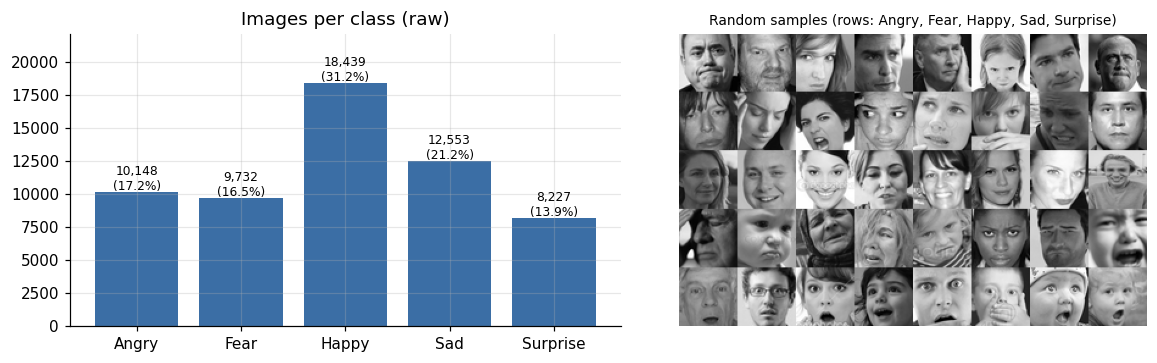

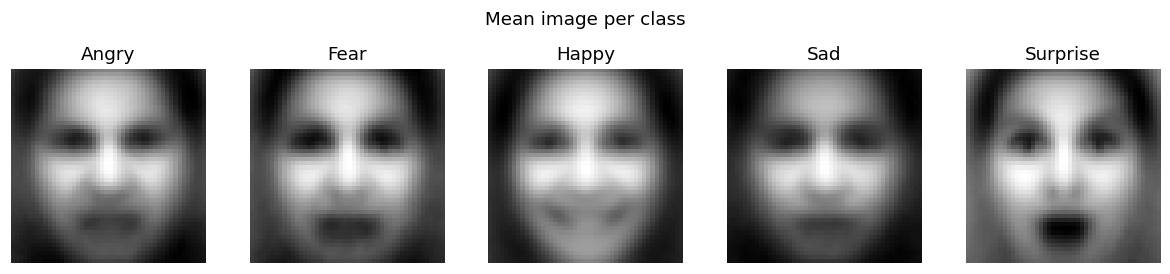

In [3]:
y_all = labels.copy()
counts = np.bincount(y_all, minlength=K)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(NAMES, counts, color=PAL)
for i, v in enumerate(counts): ax[0].text(i, v + 150, f'{v:,}\n({v / counts.sum():.1%})', ha='center', fontsize=8)
ax[0].set_title('Images per class (raw)'); ax[0].set_ylim(0, counts.max() * 1.2)
rng = np.random.RandomState(0)
grid = np.concatenate([np.concatenate([X_img[rng.choice(np.where(y_all == k)[0])] for _ in range(8)], 1) for k in range(K)], 0)
ax[1].imshow(grid, cmap='gray'); ax[1].axis('off'); ax[1].set_title('Random samples (rows: ' + ', '.join(NAMES) + ')', fontsize=9)
plt.tight_layout(); savefig('eda_classes_samples'); plt.show()

fig, ax = plt.subplots(1, K, figsize=(11, 2.4))
for k in range(K):
    ax[k].imshow(X_img[y_all == k].mean(0), cmap='gray'); ax[k].set_title(NAMES[k]); ax[k].axis('off')
plt.suptitle('Mean image per class', y=1.02); plt.tight_layout(); savefig('eda_mean_images'); plt.show()

### Duplicate check
Web-scraped face datasets often contain exact duplicates. If a duplicate lands in both train and test, the test score is
inflated; if the same image carries two different labels it is label noise. We remove exact duplicates (same 48x48 pixels)
and drop images that appear under conflicting labels.

In [4]:
hashes = pd.Series([hashlib.md5(x.tobytes()).hexdigest() for x in X_img])
dfh = pd.DataFrame({'h': hashes, 'y': y_all})
nuniq = dfh.groupby('h')['y'].nunique()
conflict = set(nuniq[nuniq > 1].index)
dup_mask = dfh.duplicated('h', keep='first')
keep = (~dfh.h.isin(conflict)) & (~dup_mask)
print(f'exact duplicate extra copies : {int(dup_mask.sum()):,}')
print(f'hashes with conflicting labels: {len(conflict):,}  (all copies removed)')
print(f'kept {int(keep.sum()):,} of {len(keep):,} images')
X_img = X_img[keep.values]; y = y_all[keep.values]
counts = np.bincount(y, minlength=K)
print('class counts after cleaning:', dict(zip(NAMES, counts.tolist())))
CLEAN_INFO = dict(total_raw=int(len(keep)), dup_removed=int(dup_mask.sum()), conflict_hashes=len(conflict), kept=int(keep.sum()),
                  class_counts=dict(zip(NAMES, counts.tolist())))

exact duplicate extra copies : 30,232
hashes with conflicting labels: 49  (all copies removed)
kept 28,818 of 59,099 images
class counts after cleaning: {'Angry': 4959, 'Fear': 4822, 'Happy': 9255, 'Sad': 6310, 'Surprise': 3472}


## 3. Train / validation / test split
Stratified 70 / 15 / 15 split (fixed seed). Any statistic learnt from data (mean / std, PCA) is fitted on **train only**.

In [5]:
idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
print('train / val / test :', len(tr), len(va), len(te))
print('majority-class (Happy) share in test:', f'{np.mean(y[te] == NAMES.index("Happy")):.3f}', '| chance for 5 balanced classes: 0.200')

train / val / test : 20172 4323 4323
majority-class (Happy) share in test: 0.321 | chance for 5 balanced classes: 0.200


## 4. Preprocessing pipelines (input representations for the MLP)
Each pipeline = a per-image transform followed by an optional statistic fitted on the training set.

| name | description |
|---|---|
| `raw01` | pixels / 255 |
| `global_z` | (pixel - global train mean) / global train std |
| `pixel_z` | per-pixel-position standardisation (train mean / std of each of the 2304 pixels) |
| `img_std` | per-image standardisation (zero mean, unit variance for each image: removes brightness / contrast) |
| `heq_std` | global histogram equalisation, then per-image standardisation |
| `clahe_std` | CLAHE (local adaptive equalisation), then per-image standardisation |
| `down24_std` | 24x24 area down-sampling (576 inputs), then per-image standardisation |
| `pca200_white` | `img_std` -> PCA(200) with whitening |
| `pca200` | `img_std` -> PCA(200) without whitening |
| `hog` | Histogram of Oriented Gradients (9 orientations, 6x6 cells, 2x2 blocks; 1764 features), standardised |
| `lbp` | Local-Binary-Pattern histograms on a 6x6 grid (360 features), standardised |
| `hog+lbp` | concatenation of the two |
| `hog_pca256` | standardised HOG -> PCA(256) |

In [6]:
def b_raw01(im): return (im.astype(np.float32) / 255).reshape(len(im), -1)
def b_imgstd(im):
    a = im.astype(np.float32); m = a.mean((1, 2), keepdims=True); s = a.std((1, 2), keepdims=True) + 1e-6
    return ((a - m) / s).reshape(len(im), -1)
def b_heq(im): return b_imgstd(np.stack([cv2.equalizeHist(x) for x in im]))
def b_clahe(im):
    cl = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)); return b_imgstd(np.stack([cl.apply(x) for x in im]))
def b_down24(im): return b_imgstd(np.stack([cv2.resize(x, (24, 24), interpolation=cv2.INTER_AREA) for x in im]))

def _hog_chunk(ch):
    return np.stack([hog(x, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2), block_norm='L2-Hys') for x in ch]).astype(np.float32)
def b_hog(im): return np.concatenate(Parallel(n_jobs=-1)(delayed(_hog_chunk)(c) for c in np.array_split(im, 48)))
def _lbp_chunk(ch):
    out = []
    for x in ch:
        l = local_binary_pattern(x, 8, 1, 'uniform').astype(int); f = []
        for i in range(0, 48, 8):
            for j in range(0, 48, 8):
                f.append(np.bincount(l[i:i + 8, j:j + 8].ravel(), minlength=10) / 64.)
        out.append(np.concatenate(f))
    return np.array(out, dtype=np.float32)
def b_lbp(im): return np.concatenate(Parallel(n_jobs=-1)(delayed(_lbp_chunk)(c) for c in np.array_split(im, 48)))

BASEFN = dict(raw01=b_raw01, imgstd=b_imgstd, heq=b_heq, clahe=b_clahe, down24=b_down24, hog=b_hog, lbp=b_lbp)
_BC = {}
def base_all(bname, flipped=False):
    """per-image features for ALL images (stateless, so no leakage); HOG/LBP are cached because they are slow"""
    imgs = np.ascontiguousarray(X_img[:, :, ::-1]) if flipped else X_img
    if bname == 'hoglbp': return np.hstack([base_all('hog', flipped), base_all('lbp', flipped)])
    if bname in ('hog', 'lbp'):
        if (bname, flipped) not in _BC: _BC[(bname, flipped)] = BASEFN[bname](imgs)
        return _BC[(bname, flipped)]
    return BASEFN[bname](imgs)

def fit_post(kind, Ftr):
    """statistics fitted on the training rows only; returns a transform function"""
    if kind == 'none': return lambda A: A
    if kind == 'gz':
        mu, sd = Ftr.mean(), Ftr.std(); return lambda A: ((A - mu) / sd).astype(np.float32)
    if kind in ('z', 'z_pca256'):
        mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
        if kind == 'z': return lambda A: ((A - mu) / sd).astype(np.float32)
        p = PCA(256, random_state=SEED).fit((Ftr - mu) / sd); s = float(np.sqrt(p.explained_variance_[0]))
        return lambda A: (p.transform((A - mu) / sd) / s).astype(np.float32)
    if kind in ('pca200w', 'pca200'):
        p = PCA(200, whiten=(kind == 'pca200w'), random_state=SEED).fit(Ftr)
        s = 1.0 if kind == 'pca200w' else float(np.sqrt(p.explained_variance_[0]))
        return lambda A: (p.transform(A) / s).astype(np.float32)

PIPE = {'raw01': ('raw01', 'none'), 'global_z': ('raw01', 'gz'), 'pixel_z': ('raw01', 'z'), 'img_std': ('imgstd', 'none'),
        'heq_std': ('heq', 'none'), 'clahe_std': ('clahe', 'none'), 'down24_std': ('down24', 'none'),
        'pca200_white': ('imgstd', 'pca200w'), 'pca200': ('imgstd', 'pca200'),
        'hog': ('hog', 'z'), 'lbp': ('lbp', 'z'), 'hog+lbp': ('hoglbp', 'z'), 'hog_pca256': ('hog', 'z_pca256')}

def build(prep, flip=False):
    bname, post = PIPE[prep]
    B = base_all(bname); fn = fit_post(post, B[tr])
    Xtr, Xva, Xte = fn(B[tr]), fn(B[va]), fn(B[te]); ytr = y[tr]
    if flip:                                                  # offline horizontal-flip augmentation of the TRAIN rows only
        Bf = base_all(bname, flipped=True)
        Xtr = np.concatenate([Xtr, fn(Bf[tr])]); ytr = np.concatenate([ytr, ytr])
    g = lambda a, dt=torch.float32: torch.tensor(np.ascontiguousarray(a), dtype=dt, device=dev)
    return g(Xtr), g(ytr, torch.long), g(Xva), g(y[va], torch.long), g(Xte), g(y[te], torch.long)

_FC = {}
def get_feats(prep, flip=False):
    key = (prep, flip)
    if key not in _FC:
        while len(_FC) >= 2: del _FC[next(iter(_FC))]
        torch.cuda.empty_cache(); _FC[key] = build(prep, flip)
    return _FC[key]

t0 = time.time()
for nm in PIPE:
    t1 = time.time(); a = get_feats(nm)[0]
    print(f'{nm:13s} dim={a.shape[1]:5d}  built in {time.time() - t1:5.1f}s')
print(f'total {time.time() - t0:.0f}s')

raw01         dim= 2304  built in   0.3s


global_z      dim= 2304  built in   0.5s


pixel_z       dim= 2304  built in   0.5s


img_std       dim= 2304  built in   0.4s


heq_std       dim= 2304  built in   0.5s


clahe_std     dim= 2304  built in   1.3s
down24_std    dim=  576  built in   0.2s


... (2 outputs left out)

hog           dim= 1764  built in   6.5s


lbp           dim=  360  built in   4.6s


hog+lbp       dim= 2124  built in   0.8s


hog_pca256    dim=  256  built in   4.0s
total 23s


Quick visual check of what the MLP "sees" for the pixel-based preprocessing variants and the HOG representation.

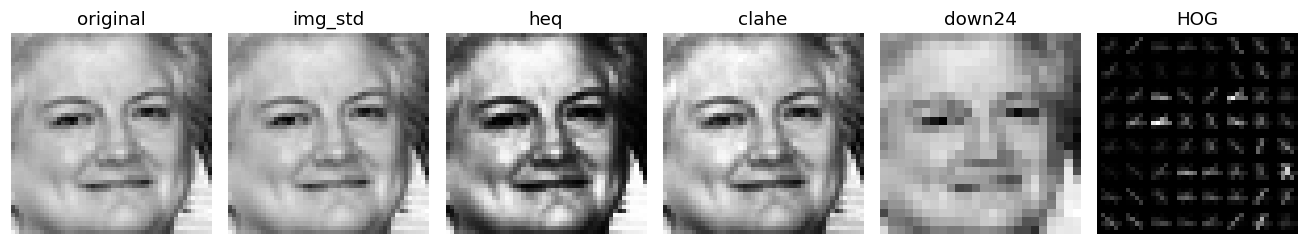

PCA(200) keeps 90.6% of the variance of the standardised pixels (2304 dims); PCA(50): 76.6%


In [7]:
i0 = np.where(y == NAMES.index('Happy'))[0][3]
im = X_img[i0:i0 + 1]
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3))
for a_, (t, v) in zip(ax, [('original', im[0]), ('img_std', b_imgstd(im).reshape(48, 48)), ('heq', cv2.equalizeHist(im[0])),
                          ('clahe', cv2.createCLAHE(2.0, (4, 4)).apply(im[0])), ('down24', cv2.resize(im[0], (24, 24), interpolation=cv2.INTER_AREA)),
                          ('HOG', hog(im[0], orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2), visualize=True)[1])]):
    a_.imshow(v, cmap='gray'); a_.set_title(t); a_.axis('off')
plt.tight_layout(); savefig('preprocessing_examples'); plt.show()
p_ = PCA(200, random_state=SEED).fit(b_imgstd(X_img[tr]))
print(f'PCA(200) keeps {p_.explained_variance_ratio_.sum():.1%} of the variance of the standardised pixels (2304 dims); PCA(50): {p_.explained_variance_ratio_[:50].sum():.1%}')

## 5. Training engine (MLP only)
* model: `Linear -> [BatchNorm] -> activation -> [Dropout]` blocks and a final `Linear(., 5)`.
* the whole dataset lives on the GPU; mini-batches are drawn by index, so a run takes seconds.
* early stopping on **validation macro-F1** (best epoch is restored); max 60 epochs, patience 10.
* every run is logged in `RUNS` (config, validation accuracy / macro-F1 / per-class recall, best epoch, time).

In [8]:
ACT = dict(relu=nn.ReLU, leaky_relu=lambda: nn.LeakyReLU(0.1), gelu=nn.GELU, elu=nn.ELU, silu=nn.SiLU, tanh=nn.Tanh, sigmoid=nn.Sigmoid)

def make_mlp(d_in, hidden, n_out, act='relu', dropout=0., bn=False):
    layers, d = [], d_in
    for h in hidden:
        layers.append(nn.Linear(d, h))
        if bn: layers.append(nn.BatchNorm1d(h))
        layers.append(ACT[act]())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers)

def metrics_t(pred, yt):
    cm = torch.bincount(yt * K + pred, minlength=K * K).view(K, K).float()
    tp = cm.diag(); prec = tp / cm.sum(0).clamp(min=1); rec = tp / cm.sum(1).clamp(min=1)
    f1 = 2 * prec * rec / (prec + rec).clamp(min=1e-9)
    return (tp.sum() / cm.sum()).item(), f1.mean().item(), rec.cpu().numpy()

def augment(xb, aug):                                        # on-the-fly augmentation for 48x48 pixel inputs
    n = xb.size(0); x = xb.view(n, 1, 48, 48)
    if 'flip' in aug:
        m = torch.rand(n, 1, 1, 1, device=dev) < 0.5; x = torch.where(m, x.flip(3), x)
    if 'affine' in aug:
        u = lambda: torch.rand(n, device=dev) * 2 - 1
        ang, sc = u() * (10 * np.pi / 180), 1 + u() * 0.1; tx, ty = u() * 0.1, u() * 0.1
        c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
        theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode='border', align_corners=False)
    return x.reshape(n, -1)

DEF = dict(hidden=(512, 256), act='relu', dropout=0., bn=False, opt='adam', lr=1e-3, wd=0., bs=256, epochs=60, patience=10,
           sched='cosine', class_weight=False, oversample=False, label_smooth=0., aug=(), in_noise=0.)

def _fit(prep, seed=0, flip=False, keep=False, frac=1.0, **cfg):
    c = {**DEF, **cfg}
    Xtr, ytr, Xva, yva, Xte, yte = get_feats(prep, flip)
    torch.manual_seed(seed); np.random.seed(seed)
    if frac < 1:
        sel = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(seed))[:int(len(Xtr) * frac)].to(dev)
        Xtr, ytr = Xtr[sel], ytr[sel]
    N, D = Xtr.shape
    if c['aug']: assert D == 2304, 'on-the-fly image augmentation needs 48x48 pixel inputs'
    model = make_mlp(D, c['hidden'], K, c['act'], c['dropout'], c['bn']).to(dev)
    P = model.parameters()
    opt = dict(adam=lambda: torch.optim.Adam(P, c['lr'], weight_decay=c['wd']),
               adamw=lambda: torch.optim.AdamW(P, c['lr'], weight_decay=c['wd']),
               sgd=lambda: torch.optim.SGD(P, c['lr'], momentum=0.9, nesterov=True, weight_decay=c['wd']),
               rmsprop=lambda: torch.optim.RMSprop(P, c['lr'], weight_decay=c['wd']))[c['opt']]()
    steps = (N + c['bs'] - 1) // c['bs']
    sch = dict(none=None, cosine=lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, c['epochs']),
               onecycle=lambda: torch.optim.lr_scheduler.OneCycleLR(opt, c['lr'], total_steps=c['epochs'] * steps, cycle_momentum=False),
               step=lambda: torch.optim.lr_scheduler.StepLR(opt, max(1, c['epochs'] // 3), 0.3))[c['sched']]
    sch = sch() if sch else None
    cnt = torch.bincount(ytr, minlength=K).float()
    cw = (N / (K * cnt)).to(dev) if c['class_weight'] else None
    sp = (1.0 / cnt)[ytr] if c['oversample'] else None
    sub = slice(0, min(8000, N)); hist = dict(tr_loss=[], va_loss=[], tr_acc=[], va_acc=[], va_f1=[])
    best, bad, state, t0 = dict(f1=-1), 0, None, time.time()
    for ep in range(c['epochs']):
        model.train()
        idx = torch.multinomial(sp, N, replacement=True) if sp is not None else torch.randperm(N, device=dev)
        tl = 0.
        for i in range(steps):
            b = idx[i * c['bs']:(i + 1) * c['bs']]
            if len(b) < 2: continue
            xb, yb = Xtr[b], ytr[b]
            if c['aug']: xb = augment(xb, c['aug'])
            if c['in_noise']: xb = xb + c['in_noise'] * torch.randn_like(xb)
            loss = F.cross_entropy(model(xb), yb, weight=cw, label_smoothing=c['label_smooth'])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tl += loss.item()
            if c['sched'] == 'onecycle': sch.step()
        if sch is not None and c['sched'] != 'onecycle': sch.step()
        model.eval()
        with torch.no_grad():
            lv = model(Xva); vl = F.cross_entropy(lv, yva).item()
            acc, f1, rec = metrics_t(lv.argmax(1), yva); tra = metrics_t(model(Xtr[sub]).argmax(1), ytr[sub])[0]
        for k, v in zip(hist, (tl / steps, vl, tra, acc, f1)): hist[k].append(v)
        if f1 > best['f1'] + 1e-4:
            best, bad = dict(f1=f1, acc=acc, rec=rec, ep=ep, tr_acc=tra), 0
            if keep: state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= c['patience']: break
    out = dict(va_f1=best['f1'], va_acc=best['acc'], recall=best['rec'], best_ep=best['ep'] + 1, tr_acc=best['tr_acc'],
               time=time.time() - t0, hist=hist, n_params=sum(p.numel() for p in model.parameters()))
    if keep:
        model.load_state_dict(state); model.eval()
        with torch.no_grad():
            out['va_prob'] = F.softmax(model(Xva), 1).cpu().numpy(); out['te_prob'] = F.softmax(model(Xte), 1).cpu().numpy()
        out['model'] = model
    return out

import pickle
CKPT = os.path.join(tempfile.gettempdir(), 'emotion_mlp_ckpt'); os.makedirs(CKPT, exist_ok=True)
def fit(prep, seed=0, flip=False, keep=False, frac=1.0, **cfg):
    """training run with an on-disk checkpoint of its result, so that the notebook can resume after a crash
    (e.g. a GPU driver fault). A checkpointed run returns exactly the numbers of the run that produced it."""
    if keep: return _fit(prep, seed, flip, keep, frac, **cfg)
    key = hashlib.md5(json.dumps([prep, seed, flip, frac, {**DEF, **cfg}], sort_keys=True, default=str).encode()).hexdigest()
    fn = os.path.join(CKPT, key + '.pkl')
    if os.path.exists(fn):
        with open(fn, 'rb') as f: return pickle.load(f)
    out = _fit(prep, seed, flip, keep, frac, **cfg)
    with open(fn, 'wb') as f: pickle.dump(out, f)
    return out

RUNS = []
def run(prep, exp, label, seeds=(0,), flip=False, **cfg):
    outs = [fit(prep, s, flip, **cfg) for s in seeds]
    m = lambda k: float(np.mean([o[k] for o in outs]))
    rec = dict(exp=exp, label=label, prep=prep, flip=flip, cfg={**DEF, **cfg}, n_seeds=len(seeds), va_acc=m('va_acc'), va_f1=m('va_f1'),
               va_f1_sd=float(np.std([o['va_f1'] for o in outs])), tr_acc=m('tr_acc'), best_ep=m('best_ep'), time=m('time'),
               n_params=outs[0]['n_params'], recall=np.mean([o['recall'] for o in outs], 0).tolist())
    RUNS.append(rec); rec['_hist'] = outs[0]['hist']
    return rec

def bars(items, title, fname, ref=None, w=7.5):
    """items = list of (label, f1, sd)"""
    fig, ax = plt.subplots(figsize=(w, 0.34 * len(items) + 1.2))
    ys = np.arange(len(items))[::-1]
    ax.barh(ys, [i[1] for i in items], xerr=[i[2] for i in items], color=PAL, alpha=.9, capsize=2)
    ax.set_yticks(ys); ax.set_yticklabels([i[0] for i in items]); lo = min(i[1] for i in items)
    ax.set_xlim(max(0, lo - 0.08), max(i[1] for i in items) + 0.03)
    for yy, i in zip(ys, items): ax.text(i[1] + 0.002, yy, f'{i[1]:.3f}', va='center', fontsize=8)
    if ref is not None: ax.axvline(ref, color='#c0392b', ls='--', lw=1)
    ax.set_xlabel('validation macro-F1'); ax.set_title(title); plt.tight_layout(); savefig(fname); plt.show()

def table(exp_prefix, extra=()):
    d = pd.DataFrame([{k: v for k, v in r.items() if k not in ('cfg', '_hist', 'recall')} for r in RUNS if r['exp'].startswith(exp_prefix)])
    return d.sort_values('va_f1', ascending=False)[['label', 'va_acc', 'va_f1', 'va_f1_sd', 'tr_acc', 'best_ep', 'n_params', 'time', *extra]].round(4)

## 6. Experiment 1 - baseline MLP
A plain MLP `2304 -> 512 -> 256 -> 5` (ReLU, Adam, lr=1e-3, batch 256, no regularisation) on raw pixels in [0,1], three seeds.

baseline: val acc 0.4704 | val macro-F1 0.4325 +- 0.0073 | train acc 0.582 | best epoch 39.0 | 1,312,773 params


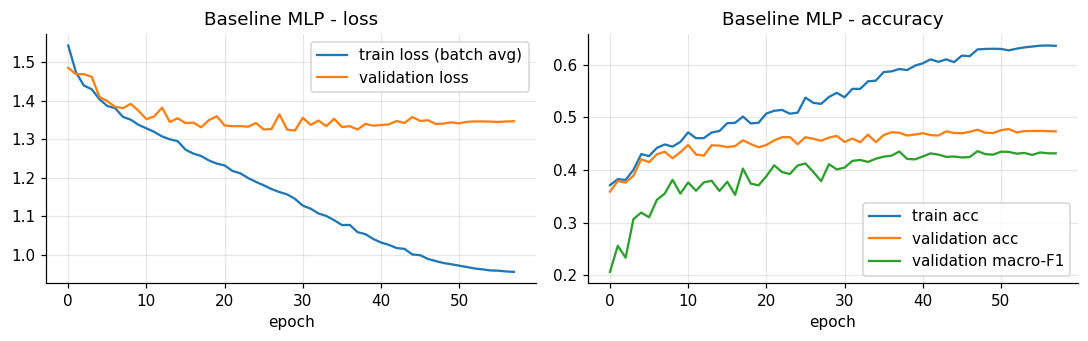

In [9]:
base = run('raw01', 'baseline', 'baseline raw01 512-256', seeds=(0, 1, 2), **DEF)
print(f"baseline: val acc {base['va_acc']:.4f} | val macro-F1 {base['va_f1']:.4f} +- {base['va_f1_sd']:.4f} | train acc {base['tr_acc']:.3f} | best epoch {base['best_ep']:.1f} | {base['n_params']:,} params")
h = base['_hist']; fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h['tr_loss'], label='train loss (batch avg)'); ax[0].plot(h['va_loss'], label='validation loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].set_title('Baseline MLP - loss')
ax[1].plot(h['tr_acc'], label='train acc'); ax[1].plot(h['va_acc'], label='validation acc'); ax[1].plot(h['va_f1'], label='validation macro-F1'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('Baseline MLP - accuracy')
plt.tight_layout(); savefig('baseline_curves'); plt.show()

**Observations.** A plain MLP on raw pixels reaches only **47.0 % validation accuracy / 0.433 macro-F1** (chance = 20 %, always predicting *Happy* = 32 %). Training accuracy keeps climbing (58 % at the best epoch, about 64 % later) while the validation loss stops improving after about 10 epochs and then stays flat at ~1.34: the network fits the training pixels but generalises poorly - a clear over-fitting signature that guides the rest of the study.

## 7. Experiment 2 - data preprocessing
Same baseline MLP, 13 different input representations, two seeds each.

,label,va_acc,va_f1,va_f1_sd,tr_acc,best_ep,n_params,time
11,hog+lbp,0.5630,0.5315,0.0009,0.9954,17.0,1220613,5.0376
9,hog,0.5611,0.5273,0.0024,0.9999,17.5,1036293,5.0544
12,hog_pca256,0.5461,0.5099,0.0027,0.8644,5.5,264197,2.9200
3,img_std,0.5005,0.4730,0.0031,0.9992,22.5,1312773,6.0472
4,heq_std,0.4998,0.4688,0.0037,0.9997,37.0,1312773,8.7547
6,down24_std,0.4918,0.4638,0.0002,0.9988,25.0,428037,6.5234
1,global_z,0.4898,0.4638,0.0001,0.9941,26.0,1312773,6.7235
2,pixel_z,0.4921,0.4638,0.0007,0.9611,22.5,1312773,6.0381
5,clahe_std,0.4840,0.4560,0.0015,0.9992,23.5,1312773,6.2223
8,pca200,0.4762,0.4431,0.0005,0.8158,9.0,235525,3.5607


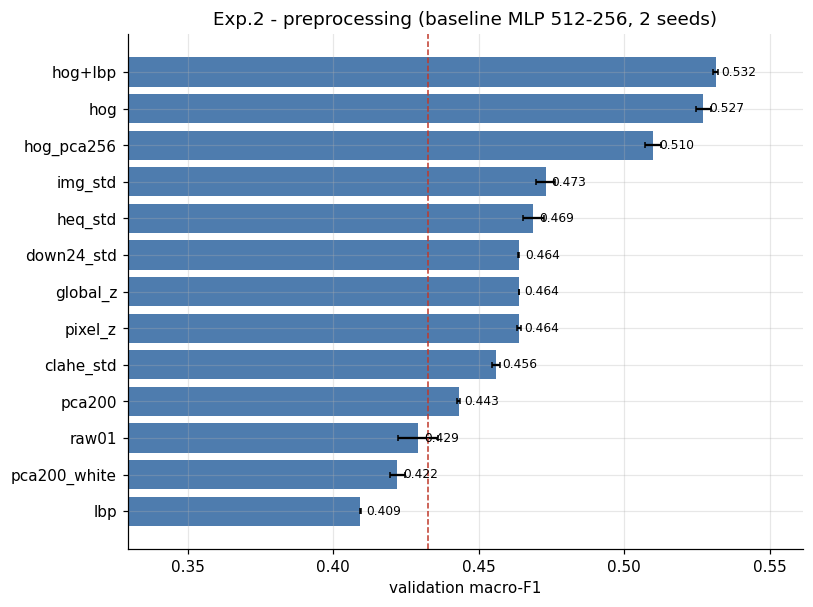

best preprocessing overall : hog+lbp | best pixel-based: img_std


In [10]:
PREPS = list(PIPE)
prep_recs = [run(p, 'prep', p, seeds=(0, 1), **DEF) for p in PREPS]
display(table('prep', ('prep',)).drop(columns=['prep']))
prep_recs_sorted = sorted(prep_recs, key=lambda r: -r['va_f1'])
bars([(r['label'], r['va_f1'], r['va_f1_sd']) for r in prep_recs_sorted], 'Exp.2 - preprocessing (baseline MLP 512-256, 2 seeds)', 'exp2_preprocessing', ref=base['va_f1'])
BEST_PREP = prep_recs_sorted[0]['prep']; BEST_PIX = max([r for r in prep_recs if PIPE[r['prep']][0] in ('raw01', 'imgstd', 'heq', 'clahe')], key=lambda r: r['va_f1'])['prep']
print('best preprocessing overall :', BEST_PREP, '| best pixel-based:', BEST_PIX)

**Observations.** The input representation matters more than anything else we tune: the best pipeline improves macro-F1 by about 10 points over the raw-pixel baseline (0.433 -> 0.532).
* **HOG (0.527) and HOG+LBP (0.532) clearly beat every pixel-based variant (0.43-0.47).** Gradient-orientation histograms are insensitive to brightness and tolerate small misalignments, which an MLP (no built-in translation invariance) cannot learn from raw pixels with this little data. LBP alone is weak (0.409) but adds a little on top of HOG.
* Among pixel variants, **per-image standardisation** (0.473) beats [0,1] scaling (0.429) by ~4 points (removes lighting / contrast differences). Histogram equalisation (0.469) is no better, CLAHE (0.456) is slightly worse (it amplifies noise at 48x48). Global or per-pixel z-scoring gives 0.464.
* 24x24 down-sampling matches the full-resolution score (0.464 vs 0.473) with 3x fewer parameters: fine detail is not being exploited.
* **PCA does not help an MLP**: 200 un-whitened components 0.443, whitened 0.422 (whitening amplifies low-variance, noisy directions).
* Almost every pipeline reaches ~100 % training accuracy (`tr_acc`): the limit is generalisation, not capacity.

## 8. Experiment 3 - architecture (depth x width, and shapes)
Run on the best preprocessing. Constant-width grids (1-4 hidden layers x 128 / 256 / 512 / 1024 units) plus some pyramid, wide-shallow and bottleneck shapes.

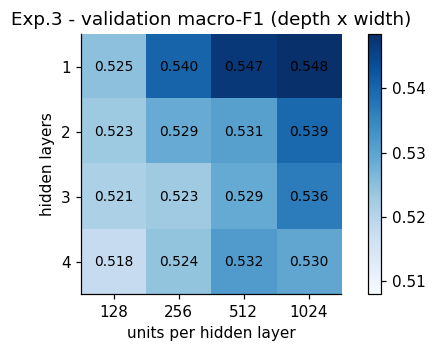

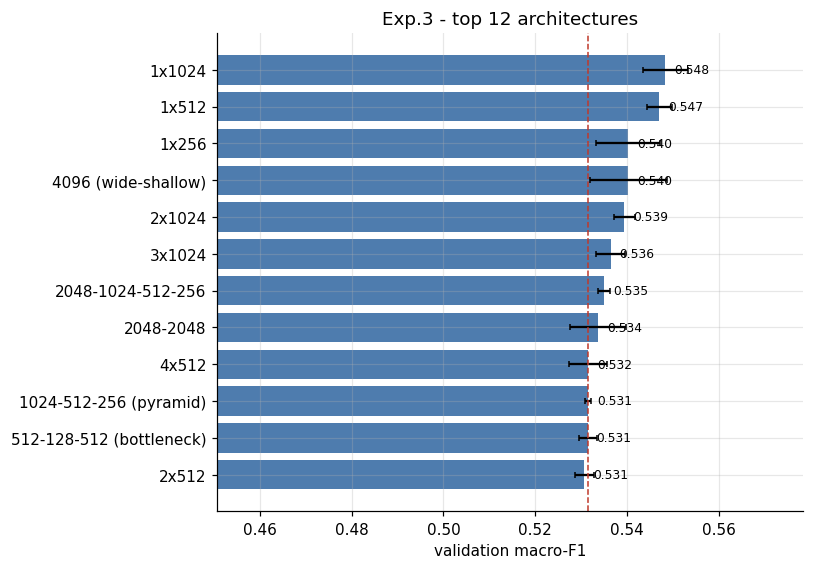

,label,va_acc,va_f1,va_f1_sd,tr_acc,best_ep,n_params,time
3,1x1024,0.5855,0.5484,0.0050,1.0000,22.0,2181125,4.9850
2,1x512,0.5822,0.5470,0.0027,0.9998,21.5,1090565,4.7242
1,1x256,0.5739,0.5403,0.0070,0.9999,16.0,545285,3.9190
16,4096 (wide-shallow),0.5704,0.5403,0.0084,0.9945,29.0,8724485,14.3067
7,2x1024,0.5723,0.5394,0.0022,1.0000,30.0,3230725,8.2562
11,3x1024,0.5681,0.5364,0.0032,0.9573,6.5,4280325,4.4119
18,2048-1024-512-256,0.5657,0.5350,0.0013,0.9861,11.5,7107589,8.4862
21,2048-2048,0.5658,0.5336,0.0061,0.9929,19.0,8558597,11.4934
14,4x512,0.5637,0.5315,0.0041,0.9894,27.0,1878533,9.8883
17,1024-512-256 (pyramid),0.5612,0.5314,0.0006,0.9633,8.0,2833413,4.3443


best architecture: (1024,)


In [11]:
arch_recs = {}
for depth in (1, 2, 3, 4):
    for width in (128, 256, 512, 1024):
        arch_recs[(depth, width)] = run(BEST_PREP, 'arch_grid', f'{depth}x{width}', seeds=(0, 1), **{**DEF, 'hidden': (width,) * depth})
shapes = {'4096 (wide-shallow)': (4096,), '1024-512-256 (pyramid)': (1024, 512, 256), '2048-1024-512-256': (2048, 1024, 512, 256),
          '512-128-512 (bottleneck)': (512, 128, 512), '256-512-1024 (expanding)': (256, 512, 1024), '2048-2048': (2048, 2048)}
shape_recs = {k: run(BEST_PREP, 'arch_shape', k, seeds=(0, 1), **{**DEF, 'hidden': v}) for k, v in shapes.items()}
grid = np.array([[arch_recs[(d, w)]['va_f1'] for w in (128, 256, 512, 1024)] for d in (1, 2, 3, 4)])
fig, ax = plt.subplots(figsize=(5.2, 3.3)); im_ = ax.imshow(grid, cmap='Blues', vmin=grid.min() - .01)
ax.set_xticks(range(4)); ax.set_xticklabels((128, 256, 512, 1024)); ax.set_yticks(range(4)); ax.set_yticklabels((1, 2, 3, 4))
ax.set_xlabel('units per hidden layer'); ax.set_ylabel('hidden layers'); ax.grid(False); ax.set_title('Exp.3 - validation macro-F1 (depth x width)')
for i in range(4):
    for j in range(4): ax.text(j, i, f'{grid[i, j]:.3f}', ha='center', va='center', fontsize=9)
plt.colorbar(im_); plt.tight_layout(); savefig('exp3_arch_grid'); plt.show()
allarch = list(arch_recs.values()) + list(shape_recs.values())
bars([(r['label'], r['va_f1'], r['va_f1_sd']) for r in sorted(allarch, key=lambda r: -r['va_f1'])[:12]], 'Exp.3 - top 12 architectures', 'exp3_arch_top', ref=prep_recs_sorted[0]['va_f1'])
display(table('arch', ('prep',)).drop(columns=['prep']).head(12))
BEST_ARCH = max(allarch, key=lambda r: r['va_f1'])['cfg']['hidden']
print('best architecture:', BEST_ARCH)

**Observations.** The best architecture is a **single wide hidden layer (1 x 1024, 0.548)**.
* For every width, adding layers does not help: with 1024 units, 1 -> 4 layers gives 0.548, 0.539, 0.536, 0.530. Narrow layers lose 2-3 points (1 x 128: 0.525). A 4096-unit single layer (0.540) costs 8.7 M parameters for no gain.
* Interpretation: after HOG/LBP the classes are already reasonably separable; extra depth mostly adds ways to memorise the ~20k training images (all models reach ~100 % training accuracy).
* The top models differ by about 1 point, which is close to the seed standard deviation (0.2-0.8 point), so their exact ranking is not significant; the trend with depth is consistent though.

## 9. Experiment 4 - activation functions

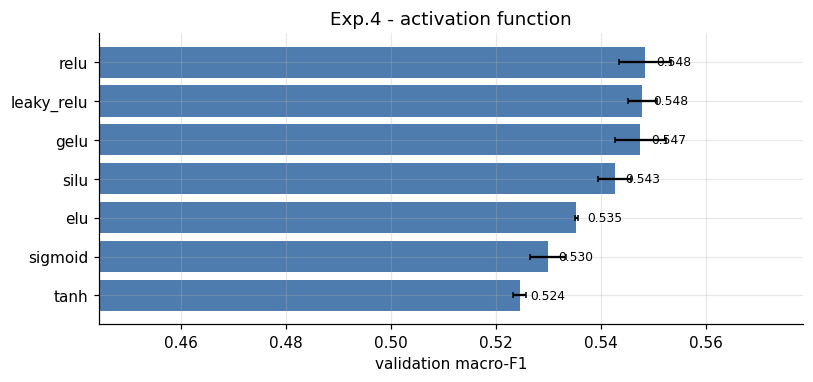

,label,va_acc,va_f1,va_f1_sd,tr_acc,best_ep,n_params,time
0,relu,0.5855,0.5484,0.0050,1.0000,22.0,2181125,4.9850
1,leaky_relu,0.5822,0.5478,0.0027,1.0000,17.5,2181125,4.4806
2,gelu,0.5813,0.5474,0.0049,0.9998,11.0,2181125,3.2805
4,silu,0.5766,0.5425,0.0032,0.9989,8.5,2181125,2.9052
3,elu,0.5703,0.5353,0.0003,1.0000,16.5,2181125,4.1914
6,sigmoid,0.5678,0.5298,0.0034,0.9999,30.5,2181125,6.3182
5,tanh,0.5603,0.5245,0.0012,0.9999,15.0,2181125,3.9646


best activation: relu


In [12]:
B1 = {**DEF, 'hidden': BEST_ARCH}
act_recs = [run(BEST_PREP, 'act', a, seeds=(0, 1), **{**B1, 'act': a}) for a in ACT]
bars([(r['label'], r['va_f1'], r['va_f1_sd']) for r in sorted(act_recs, key=lambda r: -r['va_f1'])], 'Exp.4 - activation function', 'exp4_activation')
display(table('act'))
B1['act'] = max(act_recs, key=lambda r: r['va_f1'])['label']
print('best activation:', B1['act'])

**Observations.** ReLU (0.548), Leaky-ReLU (0.548) and GELU (0.547) are statistically tied; SiLU is slightly lower (0.543) and ELU lower still (0.535). The saturating activations are the worst (sigmoid 0.530, tanh 0.525, i.e. ~2-2.5 points below ReLU). We keep ReLU.

## 10. Experiment 5 - regularisation (dropout, batch-norm, weight decay, label smoothing, input noise)
One-factor-at-a-time around the current best configuration; a factor value is adopted only if it improves
validation macro-F1 by > 0.003 (about the seed noise); the adopted values are then combined and re-checked.

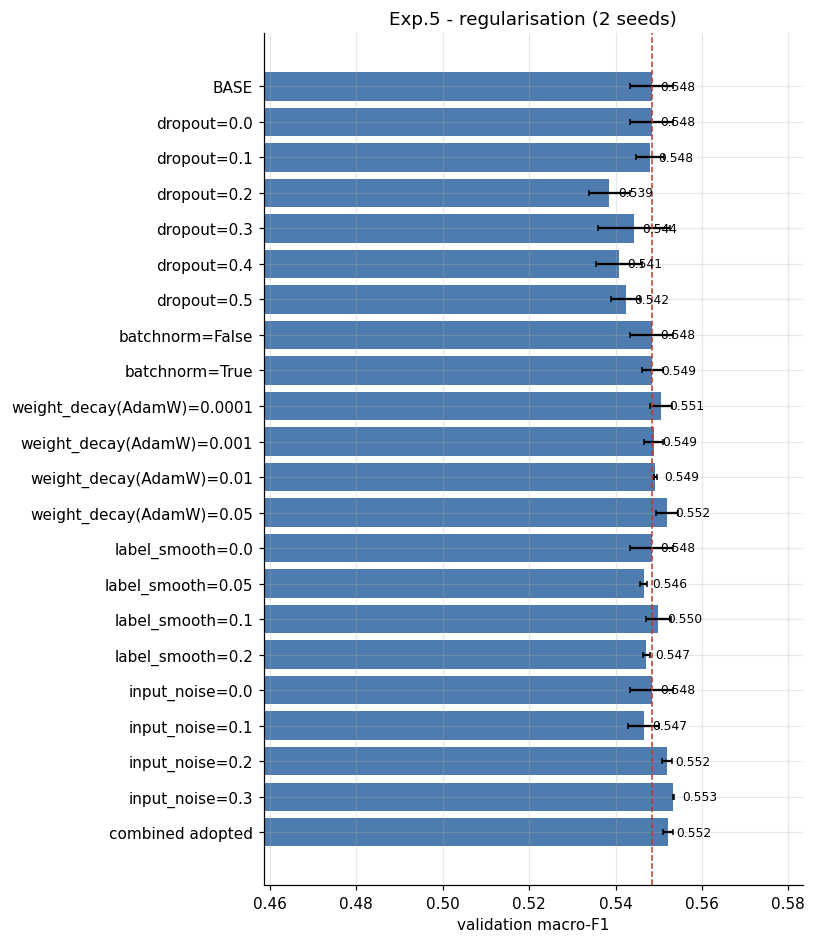

adopted: {'opt': 'adamw', 'wd': 0.05, 'in_noise': 0.3} | base F1 0.5484 -> combined F1 0.5522


In [13]:
def sweep(prep, exp, base_cfg, factors, seeds=(0, 1), thr=0.003):
    base_rec = run(prep, f'{exp}', 'base', seeds=seeds, **base_cfg); res, adopt = {}, {}
    for fname, opts in factors.items():
        recs = []
        for lab, ch in opts:
            same = all(base_cfg.get(k) == v for k, v in ch.items())
            recs.append((f'{fname}={lab}', base_rec if same else run(prep, f'{exp}', f'{fname}={lab}', seeds=seeds, **{**base_cfg, **ch}), ch))
        res[fname] = recs; b = max(recs, key=lambda t: t[1]['va_f1'])
        if b[1]['va_f1'] > base_rec['va_f1'] + thr: adopt.update(b[2])
    comb = {**base_cfg, **adopt}
    comb_rec = run(prep, f'{exp}', 'combined adopted', seeds=seeds, **comb) if adopt else base_rec
    chosen = comb if comb_rec['va_f1'] >= base_rec['va_f1'] else base_cfg
    return chosen, base_rec, comb_rec, res, adopt

def plot_factors(res, base_rec, comb_rec, title, fname):
    items = [('BASE', base_rec['va_f1'], base_rec['va_f1_sd'])] + [(lab, r['va_f1'], r['va_f1_sd']) for fl in res.values() for lab, r, _ in fl] + [('combined adopted', comb_rec['va_f1'], comb_rec['va_f1_sd'])]
    seen, uniq = set(), []
    for it in items:
        if it[0] not in seen: seen.add(it[0]); uniq.append(it)
    bars(uniq, title, fname, ref=base_rec['va_f1'], w=7.5)

reg_factors = {'dropout': [(d, {'dropout': d}) for d in (0., .1, .2, .3, .4, .5)],
               'batchnorm': [(b, {'bn': b}) for b in (False, True)],
               'weight_decay(AdamW)': [(w, {'opt': 'adamw', 'wd': w}) for w in (1e-4, 1e-3, 1e-2, 5e-2)],
               'label_smooth': [(s, {'label_smooth': s}) for s in (0., .05, .1, .2)],
               'input_noise': [(s, {'in_noise': s}) for s in (0., .1, .2, .3)]}
B2, reg_base, reg_comb, reg_res, reg_adopt = sweep(BEST_PREP, 'reg', B1, reg_factors)
plot_factors(reg_res, reg_base, reg_comb, 'Exp.5 - regularisation (2 seeds)', 'exp5_regularisation')
print('adopted:', reg_adopt, '| base F1 %.4f -> combined F1 %.4f' % (reg_base['va_f1'], reg_comb['va_f1']))

**Observations.** Regularisation barely moves the score: every single factor is within about +-0.5 point of the base (0.548), i.e. inside the seed noise (std up to 0.8 point).
* Dropout (0.1-0.5: 0.539-0.548), batch-norm (0.5485) and label smoothing (0.547-0.550) are neutral for this one-layer model.
* Only strong AdamW weight decay (0.05: 0.552) and heavy Gaussian input noise (sigma = 0.3: 0.553) pass the adoption threshold; combined they give 0.552 (+0.4 point).
* Training accuracy stays at ~100 % in every case: a 2.2 M-parameter model on ~20k images cannot be stopped from memorising with simple regularisers, and the train / validation gap (~40 points) remains. More data or invariance (augmentation, Exp. 8) helps more than weight penalties.

## 11. Experiment 6 - optimiser, learning rate, batch size, LR schedule

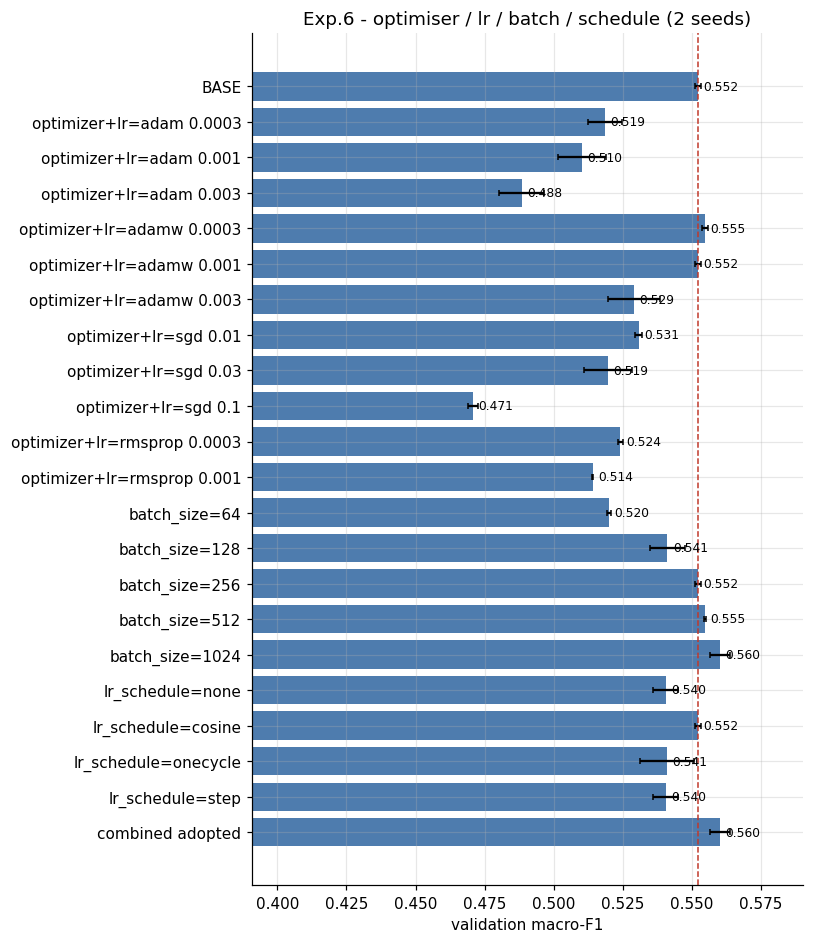

adopted: {'bs': 1024} | base F1 0.5522 -> combined F1 0.5602


In [14]:
opt_factors = {'optimizer+lr': [(f'{o} {l:g}', {'opt': o, 'lr': l}) for o, ls in (('adam', (3e-4, 1e-3, 3e-3)), ('adamw', (3e-4, 1e-3, 3e-3)), ('sgd', (.01, .03, .1)), ('rmsprop', (3e-4, 1e-3))) for l in ls],
               'batch_size': [(b, {'bs': b}) for b in (64, 128, 256, 512, 1024)],
               'lr_schedule': [(s, {'sched': s}) for s in ('none', 'cosine', 'onecycle', 'step')]}
B3, opt_base, opt_comb, opt_res, opt_adopt = sweep(BEST_PREP, 'opt', B2, opt_factors)
plot_factors(opt_res, opt_base, opt_comb, 'Exp.6 - optimiser / lr / batch / schedule (2 seeds)', 'exp6_optimisation')
print('adopted:', opt_adopt, '| base F1 %.4f -> combined F1 %.4f' % (opt_base['va_f1'], opt_comb['va_f1']))

**Observations.**
* **Caveat:** the base uses AdamW with weight decay 0.05 (adopted in Exp. 5). For Adam, SGD and RMSprop the same value acts as a *coupled L2 penalty*, which is far too strong for them (their training accuracy is only 56-75 %). Their lower scores (Adam 0.488-0.519, SGD 0.471-0.531, RMSprop 0.514-0.524) therefore partly reflect this confound and should not be read as "AdamW is inherently better".
* AdamW at lr 3e-4 and 1e-3 are tied (0.5546 / 0.5522); 3e-3 is too high (0.529).
* **Batch size is the most influential setting here**: 64 -> 0.520, 128 -> 0.541, 256 -> 0.552, 512 -> 0.555, 1024 -> 0.560. Larger batches (less noisy gradients) generalise better; bs = 1024 is adopted (+0.8 point).
* LR schedule: `none` and `step` give identical numbers because early stopping ends training (~10 epochs) before the first step decay; cosine (0.552) is ~1 point better than none / one-cycle (0.541).

## 12. Experiment 7 - class imbalance
*Happy* has ~2.2x more images than *Surprise*. Options: nothing, class-weighted loss, or over-sampling the rare classes each epoch.
The per-class recall shows what changes.

,Angry,Fear,Happy,Sad,Surprise,val acc,val macro-F1
none,0.465,0.355,0.821,0.534,0.607,0.593,0.558
class-weighted loss,0.470,0.358,0.800,0.533,0.623,0.589,0.556
oversampling,0.478,0.352,0.811,0.521,0.608,0.589,0.555


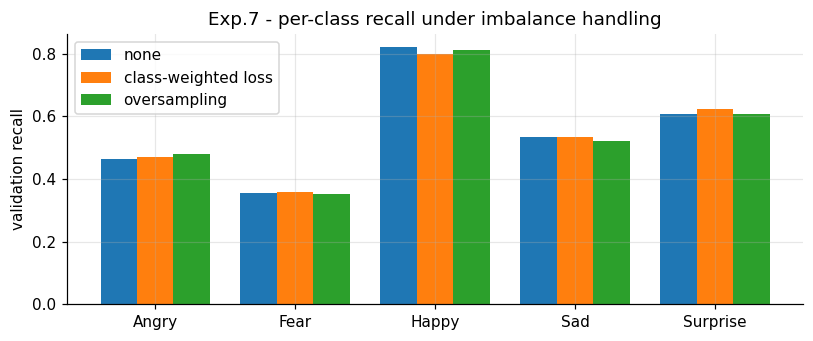

best option: none | adopted config changes: {'class_weight': False, 'oversample': False}


In [15]:
imb_opts = {'none': {}, 'class-weighted loss': {'class_weight': True}, 'oversampling': {'oversample': True}}
imb_recs = {k: run(BEST_PREP, 'imbalance', k, seeds=(0, 1, 2), **{**B3, **v}) for k, v in imb_opts.items()}
rec_tab = pd.DataFrame({k: r['recall'] for k, r in imb_recs.items()}, index=NAMES).T
rec_tab['val acc'] = [r['va_acc'] for r in imb_recs.values()]; rec_tab['val macro-F1'] = [r['va_f1'] for r in imb_recs.values()]
display(rec_tab.round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.2)); wd = .26
for i, (k, r) in enumerate(imb_recs.items()): ax.bar(np.arange(K) + (i - 1) * wd, r['recall'], wd, label=k)
ax.set_xticks(range(K)); ax.set_xticklabels(NAMES); ax.set_ylabel('validation recall'); ax.legend(); ax.set_title('Exp.7 - per-class recall under imbalance handling')
plt.tight_layout(); savefig('exp7_imbalance'); plt.show()
best_imb = max(imb_recs.items(), key=lambda kv: kv[1]['va_f1'])
B4 = {**B3, **imb_opts[best_imb[0]]} if best_imb[1]['va_f1'] > imb_recs['none']['va_f1'] + 0.003 else B3
print('best option:', best_imb[0], '| adopted config changes:', {k: B4[k] for k in ('class_weight', 'oversample')})

**Observations.** Class weighting and over-sampling do not change macro-F1 (none 0.558, weighted 0.556, over-sampled 0.555). They only shift recall slightly (Surprise 0.607 -> 0.623 with weights, Angry 0.465 -> 0.478 with over-sampling) at the cost of *Happy* recall (0.821 -> 0.800-0.811). The difficulty is not the class frequencies but class *confusability*: Fear stays the hardest class (recall ~0.35) under every option. Not adopted.

## 13. Experiment 8 - data augmentation
(a) *offline* horizontal-flip augmentation (flipped copies of the training images are added; works for any representation incl. HOG);
(b) *on-the-fly* flip / random affine (+-10 deg, +-10 % scale, +-10 % shift) / Gaussian input noise on pixel inputs (`img_std`).

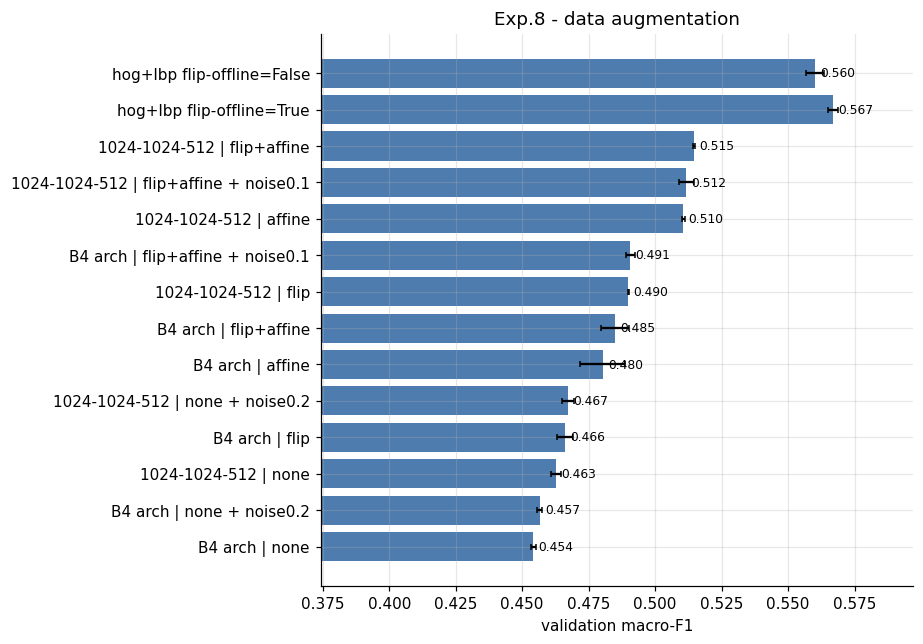

,label,va_acc,va_f1,tr_acc,best_ep
1,hog+lbp flip-offline=True,0.6000,0.5670,1.0000,34.0
0,hog+lbp flip-offline=False,0.5952,0.5602,0.9999,23.5
12,1024-1024-512 | flip+affine,0.5428,0.5147,0.9196,63.0
13,1024-1024-512 | flip+affine + noise0.1,0.5399,0.5117,0.9142,65.5
10,1024-1024-512 | affine,0.5385,0.5105,0.9911,56.5
7,B4 arch | flip+affine + noise0.1,0.5331,0.4906,0.6579,71.5
9,1024-1024-512 | flip,0.5164,0.4899,0.9997,49.0
6,B4 arch | flip+affine,0.5273,0.4849,0.6316,59.5
4,B4 arch | affine,0.5145,0.4802,0.7336,49.5
11,1024-1024-512 | none + noise0.2,0.4954,0.4673,0.9995,35.0


In [16]:
aug_off = [run(BEST_PREP, 'aug_flip_offline', f'{BEST_PREP} flip-offline={fl}', seeds=(0, 1), flip=fl, **B4) for fl in (False, True)]
big = {**B4, 'hidden': (1024, 1024, 512), 'epochs': 80, 'patience': 14}
aug_otf = []
for nm, cfgd in (('B4 arch', {**B4, 'epochs': 80, 'patience': 14}), ('1024-1024-512', big)):
    for aug, noise in ((( ), 0.), (('flip',), 0.), (('affine',), 0.), ((), .2), (('flip', 'affine'), 0.), (('flip', 'affine'), .1)):
        lab = f'{nm} | ' + ('+'.join(aug) or 'none') + (f' + noise{noise}' if noise else '')
        aug_otf.append(run('img_std', 'aug_otf', lab, seeds=(0, 1), **{**cfgd, 'aug': aug, 'in_noise': noise}))
bars([(r['label'], r['va_f1'], r['va_f1_sd']) for r in aug_off] + [(r['label'], r['va_f1'], r['va_f1_sd']) for r in sorted(aug_otf, key=lambda r: -r['va_f1'])],
     'Exp.8 - data augmentation', 'exp8_augmentation', w=8.5)
display(table('aug')[['label', 'va_acc', 'va_f1', 'tr_acc', 'best_ep']])
USE_FLIP = aug_off[1]['va_f1'] > aug_off[0]['va_f1'] + 0.003

**Observations.**
* **Offline horizontal flip on HOG+LBP** (flipped copies of the training images added): 0.560 -> 0.567 macro-F1 (accuracy 0.595 -> 0.600), a small but consistent gain; adopted.
* **On-the-fly augmentation on raw pixels helps a lot when the network is large**: the 1024-1024-512 MLP goes from 0.463 (none) to 0.515 (flip + affine), and training accuracy drops from 100 % to 92 %, i.e. augmentation really does reduce memorisation. The single-layer model gains too (0.454 -> 0.485) but under-fits (training accuracy 63 %) within 80 epochs. Gaussian noise alone gives a negligible gain.
* Even the best augmented pixel MLP (0.515) stays clearly below the HOG+LBP MLP (0.560-0.567), so hand-crafted gradient features remain the better input for an MLP.

## 14. Experiment 9 - joint random search
One-factor tuning ignores interactions, so we also run a random search (30 trials) over the joint space on the best preprocessing
(trial 0 is the greedy best configuration found so far).

trial 00  F1 0.5689  acc 0.6017  (1024,) relu do=0.0 bn=False adamw lr=0.0010 wd=5.0e-02 bs=1024 ls=0.0 cw=False flip=True


trial 01  F1 0.5381  acc 0.5667  (512, 512, 512, 512) relu do=0.1 bn=False adamw lr=0.0006 wd=2.1e-05 bs=128 ls=0.05 cw=False flip=False


trial 02  F1 0.5475  acc 0.5788  (1024, 512) relu do=0.4 bn=False adamw lr=0.0014 wd=3.1e-03 bs=128 ls=0.0 cw=True flip=False


trial 03  F1 0.5432  acc 0.5753  (1024, 512, 256) leaky_relu do=0.5 bn=False adam lr=0.0005 wd=0.0e+00 bs=256 ls=0.0 cw=True flip=False


trial 04  F1 0.5560  acc 0.5857  (512,) gelu do=0.4 bn=False adamw lr=0.0009 wd=5.7e-05 bs=128 ls=0.0 cw=True flip=True


trial 05  F1 0.5534  acc 0.5878  (1024, 512, 256) relu do=0.4 bn=True adamw lr=0.0008 wd=3.5e-02 bs=512 ls=0.05 cw=True flip=False


... (20 outputs left out)

trial 26  F1 0.5483  acc 0.5760  (512, 512, 512, 512) gelu do=0.2 bn=False adamw lr=0.0015 wd=8.9e-04 bs=128 ls=0.1 cw=True flip=False


trial 27  F1 0.5729  acc 0.6005  (1024, 1024, 1024) relu do=0.3 bn=False adam lr=0.0005 wd=0.0e+00 bs=256 ls=0.1 cw=False flip=True


trial 28  F1 0.5653  acc 0.5968  (1024,) relu do=0.4 bn=False adamw lr=0.0004 wd=2.3e-04 bs=512 ls=0.0 cw=True flip=True


trial 29  F1 0.5641  acc 0.5952  (1024, 512, 256) leaky_relu do=0.1 bn=False adam lr=0.0003 wd=0.0e+00 bs=256 ls=0.1 cw=True flip=True


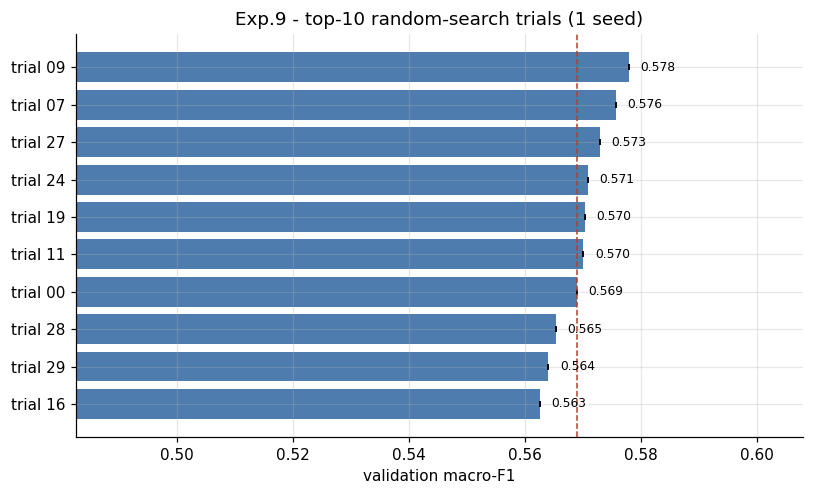

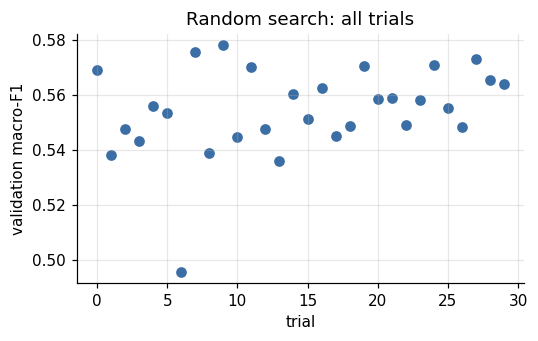

In [17]:
rs = np.random.RandomState(7)
SPACE = dict(hidden=[(512,), (1024,), (1024, 512), (512, 256), (1024, 512, 256), (2048, 1024, 512), (1024, 1024, 1024), (512, 512, 512, 512)],
             act=['relu', 'gelu', 'silu', 'leaky_relu'], dropout=[0., .1, .2, .3, .4, .5], bn=[False, True], opt=['adam', 'adamw'],
             bs=[128, 256, 512], label_smooth=[0., .05, .1], class_weight=[False, True])
best_prep_flip = USE_FLIP
trials = [dict(B4)]
for _ in range(29):
    t = {k: v[rs.randint(len(v))] for k, v in SPACE.items()}
    t['lr'] = float(10 ** rs.uniform(np.log10(3e-4), np.log10(3e-3))); t['wd'] = float(10 ** rs.uniform(-5, -1.3)) if t['opt'] == 'adamw' else 0.
    t['flip'] = bool(rs.randint(2)); trials.append({**DEF, **t})
rs_recs = []
for i, t in enumerate(trials):
    t = dict(t); fl = t.pop('flip', USE_FLIP if i == 0 else False)
    rs_recs.append(run(BEST_PREP, 'random_search', f'trial {i:02d}', seeds=(0,), flip=fl, **t))
    r = rs_recs[-1]; print(f"trial {i:02d}  F1 {r['va_f1']:.4f}  acc {r['va_acc']:.4f}  {r['cfg']['hidden']} {r['cfg']['act']} do={r['cfg']['dropout']} bn={r['cfg']['bn']} {r['cfg']['opt']} lr={r['cfg']['lr']:.4f} wd={r['cfg']['wd']:.1e} bs={r['cfg']['bs']} ls={r['cfg']['label_smooth']} cw={r['cfg']['class_weight']} flip={fl}")
top = sorted(rs_recs, key=lambda r: -r['va_f1'])[:10]
bars([(r['label'], r['va_f1'], 0) for r in top], 'Exp.9 - top-10 random-search trials (1 seed)', 'exp9_random_search_top', ref=rs_recs[0]['va_f1'])
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.scatter(range(len(rs_recs)), [r['va_f1'] for r in rs_recs], color=PAL); ax.set_xlabel('trial'); ax.set_ylabel('validation macro-F1'); ax.set_title('Random search: all trials')
plt.tight_layout(); savefig('exp9_random_search_all'); plt.show()

**Observations.** The best random-search trials reach 0.570-0.578 validation macro-F1 (one seed), about 1 point above the greedy configuration (trial 0: 0.569).
* All five best trials use **flip augmentation**, **at least two hidden layers** and (4 of 5) **batch-norm** and (4 of 5) **label smoothing 0.1**, together with dropout 0.1-0.5. So once strong regularisation and flip augmentation are present, depth no longer hurts - an *interaction* that the one-factor-at-a-time sweeps could not reveal.
* Re-checking the five best with three fresh seeds shrinks the spread to 0.567-0.575 (trial 09 drops from 0.578 to 0.571): the top configurations are statistically indistinguishable, and the first-seed numbers were optimistic (winner's curse). Performance has plateaued at about 0.57 validation macro-F1 / 0.60 accuracy for this input representation.

## 15. Cross-check with scikit-learn's `MLPClassifier`
Independent implementation (CPU, adam, early stopping on an internal 10 % validation split) on the best preprocessing, and on the compact PCA features.

In [18]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score
sk_rows = []
for nm in (BEST_PREP, 'pca200_white'):
    Xtr_, ytr_, Xva_, yva_, _, _ = [t.cpu().numpy() for t in get_feats(nm)]
    t0 = time.time()
    clf = MLPClassifier(hidden_layer_sizes=(512, 256), alpha=1e-3, batch_size=256, early_stopping=True, n_iter_no_change=6, max_iter=40, random_state=0).fit(Xtr_, ytr_)
    p_ = clf.predict(Xva_); sk_rows.append(dict(features=nm, val_acc=accuracy_score(yva_, p_), val_f1=f1_score(yva_, p_, average='macro'), epochs=clf.n_iter_, sec=time.time() - t0))
display(pd.DataFrame(sk_rows).round(4))

,features,val_acc,val_f1,epochs,sec
0,hog+lbp,0.5584,0.5244,17,48.2773
1,pca200_white,0.4483,0.4068,12,13.7833


## 16. Final model selection and test evaluation
1. Take the 5 best distinct configurations seen in *any* experiment (by validation macro-F1, mostly single-seed numbers -> optimistic).
2. Re-train each with three fresh seeds to remove the winner's curse; keep the best mean.
3. Train the winner with 5 more seeds; evaluate each seed **and the 5-seed average-probability ensemble (still just MLPs)** on the untouched test set.

In [19]:
cand = []
for r in sorted(RUNS, key=lambda r: -r['va_f1']):
    key = json.dumps([r['prep'], r['flip'], r['cfg']], sort_keys=True, default=str)
    if key not in [k for k, _ in cand] and r['exp'] not in ('prep',): cand.append((key, r))
    if len(cand) == 5: break
rechecked = []
for k, r in cand:
    cfg = {**r['cfg'], 'hidden': tuple(r['cfg']['hidden']), 'aug': tuple(r['cfg']['aug'])}
    rr = run(r['prep'], 'final_recheck', f"{r['exp']}/{r['label']}", seeds=(10, 11, 12), flip=r['flip'], **cfg)
    rechecked.append(rr); print(f"{r['exp']:>16s} / {r['label']:<28s} 1st F1 {r['va_f1']:.4f} -> re-check (3 fresh seeds) F1 {rr['va_f1']:.4f} +- {rr['va_f1_sd']:.4f}  acc {rr['va_acc']:.4f}")
FINAL = max(rechecked, key=lambda r: r['va_f1'])
FC = {**FINAL['cfg'], 'hidden': tuple(FINAL['cfg']['hidden']), 'aug': tuple(FINAL['cfg']['aug'])}
print('\nFINAL configuration:'); print('  preprocessing:', FINAL['prep'], '| flip-augmentation:', FINAL['flip']); print('  ', {k: v for k, v in FC.items()})

   random_search / trial 09                     1st F1 0.5780 -> re-check (3 fresh seeds) F1 0.5707 +- 0.0039  acc 0.5997


   random_search / trial 07                     1st F1 0.5757 -> re-check (3 fresh seeds) F1 0.5744 +- 0.0021  acc 0.6006


   random_search / trial 27                     1st F1 0.5729 -> re-check (3 fresh seeds) F1 0.5673 +- 0.0038  acc 0.5976


   random_search / trial 24                     1st F1 0.5709 -> re-check (3 fresh seeds) F1 0.5709 +- 0.0041  acc 0.6026


   random_search / trial 19                     1st F1 0.5703 -> re-check (3 fresh seeds) F1 0.5747 +- 0.0009  acc 0.6074

FINAL configuration:
  preprocessing: hog+lbp | flip-augmentation: True
   {'hidden': (1024, 512), 'act': 'gelu', 'dropout': 0.1, 'bn': True, 'opt': 'adamw', 'lr': 0.0028945895321511378, 'wd': 0.0020261274915203886, 'bs': 256, 'epochs': 60, 'patience': 10, 'sched': 'cosine', 'class_weight': False, 'oversample': False, 'label_smooth': 0.1, 'aug': (), 'in_noise': 0.0}


In [20]:
finals = [fit(FINAL['prep'], s, FINAL['flip'], keep=True, **FC) for s in (100, 101, 102, 103, 104)]
yte_np = y[te]
def mets(prob):
    p = prob.argmax(1); cm = confusion_matrix(yte_np, p, labels=range(K))
    tp = np.diag(cm); pr = tp / np.maximum(cm.sum(0), 1); rc = tp / np.maximum(cm.sum(1), 1); f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    return float((p == yte_np).mean()), float(f1.mean())
seed_res = [mets(f['te_prob']) for f in finals]
ens_prob = np.mean([f['te_prob'] for f in finals], 0); ens_acc, ens_f1 = mets(ens_prob)
print('per-seed TEST accuracy :', [round(a, 4) for a, _ in seed_res], '| mean %.4f +- %.4f' % (np.mean([a for a, _ in seed_res]), np.std([a for a, _ in seed_res])))
print('per-seed TEST macro-F1 :', [round(f, 4) for _, f in seed_res], '| mean %.4f +- %.4f' % (np.mean([f for _, f in seed_res]), np.std([f for _, f in seed_res])))
print(f'5-MLP ensemble  TEST accuracy {ens_acc:.4f} | macro-F1 {ens_f1:.4f}')
print('validation (single models) acc %.4f / macro-F1 %.4f' % (np.mean([f['va_acc'] for f in finals]), np.mean([f['va_f1'] for f in finals])), '| parameters:', f"{finals[0]['n_params']:,}")
print('reference: majority-class test accuracy %.4f ; baseline MLP (raw pixels, val) acc %.4f / F1 %.4f' % (np.mean(yte_np == np.bincount(yte_np).argmax()), base['va_acc'], base['va_f1']))

per-seed TEST accuracy : [0.6007, 0.6033, 0.5968, 0.5982, 0.6047] | mean 0.6007 +- 0.0030
per-seed TEST macro-F1 : [0.573, 0.5778, 0.5683, 0.5697, 0.576] | mean 0.5730 +- 0.0036
5-MLP ensemble  TEST accuracy 0.6218 | macro-F1 0.5930
validation (single models) acc 0.6048 / macro-F1 0.5722 | parameters: 2,706,437
reference: majority-class test accuracy 0.3211 ; baseline MLP (raw pixels, val) acc 0.4704 / F1 0.4325


              precision    recall  f1-score   support

       Angry      0.506     0.487     0.496       744
        Fear      0.476     0.401     0.435       724
       Happy      0.771     0.823     0.796      1388
         Sad      0.534     0.589     0.561       947
    Surprise      0.712     0.646     0.677       520

    accuracy                          0.622      4323
   macro avg      0.600     0.589     0.593      4323
weighted avg      0.617     0.622     0.618      4323



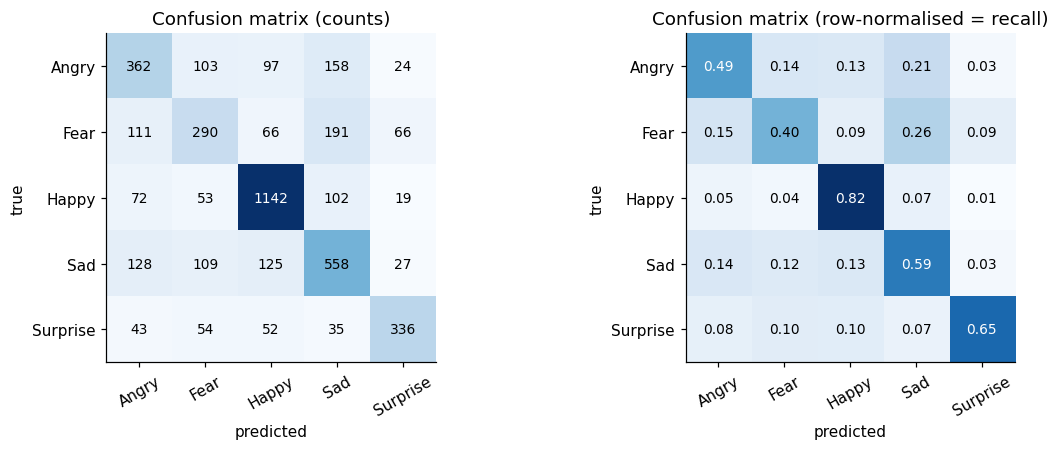

most frequent confusions (count, true -> predicted):
   191  Fear -> Sad
   158  Angry -> Sad
   128  Sad -> Angry
   125  Sad -> Happy
   111  Fear -> Angry


[None, None, None, None, None]

In [21]:
pred = ens_prob.argmax(1)
print(classification_report(yte_np, pred, target_names=NAMES, digits=3))
cm = confusion_matrix(yte_np, pred); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a_, M, t, fmt in ((ax[0], cm, 'Confusion matrix (counts)', '{:d}'), (ax[1], cmn, 'Confusion matrix (row-normalised = recall)', '{:.2f}')):
    a_.imshow(M, cmap='Blues'); a_.set_xticks(range(K)); a_.set_xticklabels(NAMES, rotation=30); a_.set_yticks(range(K)); a_.set_yticklabels(NAMES)
    a_.set_xlabel('predicted'); a_.set_ylabel('true'); a_.grid(False); a_.set_title(t)
    for i in range(K):
        for j in range(K): a_.text(j, i, fmt.format(M[i, j]), ha='center', va='center', color='white' if M[i, j] > M.max() * .55 else 'black', fontsize=9)
plt.tight_layout(); savefig('final_confusion'); plt.show()
pairs = sorted([(cm[i, j], NAMES[i], NAMES[j]) for i in range(K) for j in range(K) if i != j], reverse=True)[:5]
print('most frequent confusions (count, true -> predicted):'); [print(f'  {c:4d}  {a} -> {b}') for c, a, b in pairs]

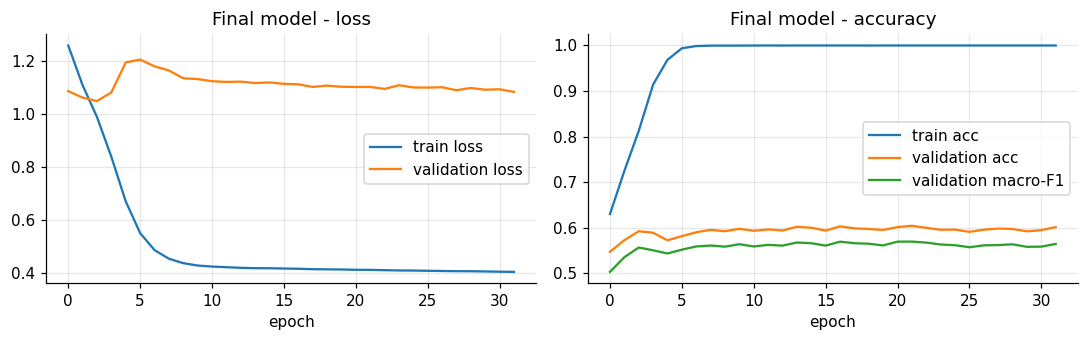

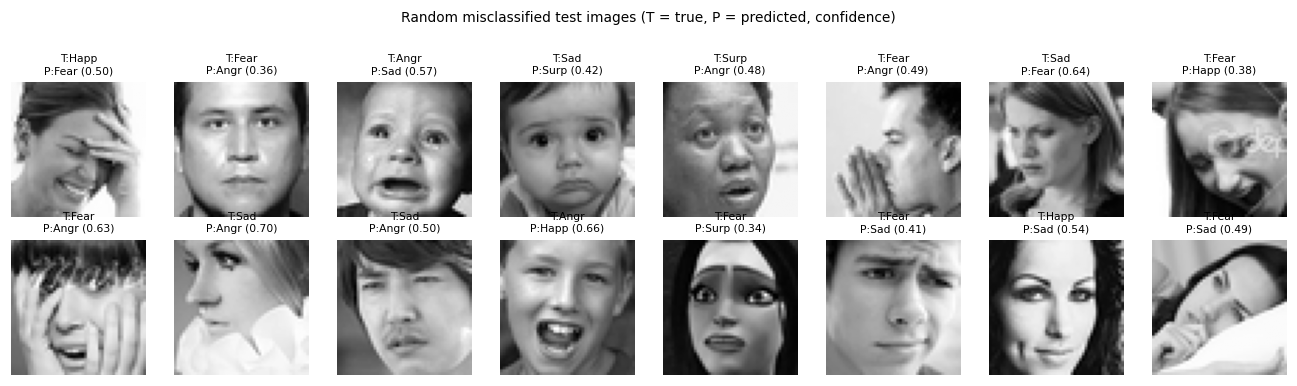

mean confidence: correct 0.705 | wrong 0.529


In [22]:
h = finals[0]['hist']; fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h['tr_loss'], label='train loss'); ax[0].plot(h['va_loss'], label='validation loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].set_title('Final model - loss')
ax[1].plot(h['tr_acc'], label='train acc'); ax[1].plot(h['va_acc'], label='validation acc'); ax[1].plot(h['va_f1'], label='validation macro-F1'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('Final model - accuracy')
plt.tight_layout(); savefig('final_curves'); plt.show()
# misclassified examples
wrong = np.where(pred != yte_np)[0]; rs2 = np.random.RandomState(1); pick = rs2.choice(wrong, 16, replace=False)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for a_, i in zip(ax.ravel(), pick):
    a_.imshow(X_img[te][i], cmap='gray'); a_.axis('off'); a_.set_title(f'T:{NAMES[yte_np[i]][:4]}\nP:{NAMES[pred[i]][:4]} ({ens_prob[i].max():.2f})', fontsize=7)
plt.suptitle('Random misclassified test images (T = true, P = predicted, confidence)', y=1.02, fontsize=9); plt.tight_layout(); savefig('final_errors'); plt.show()
conf = ens_prob.max(1); print(f'mean confidence: correct {conf[pred == yte_np].mean():.3f} | wrong {conf[pred != yte_np].mean():.3f}')

## 17. Additional analyses

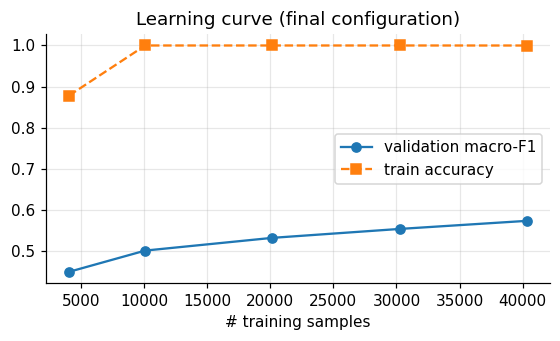

[(0.1, 0.4505, 0.878), (0.25, 0.5022, 1.0), (0.5, 0.5332, 1.0), (0.75, 0.5548, 1.0), (1.0, 0.5744, 1.0)]


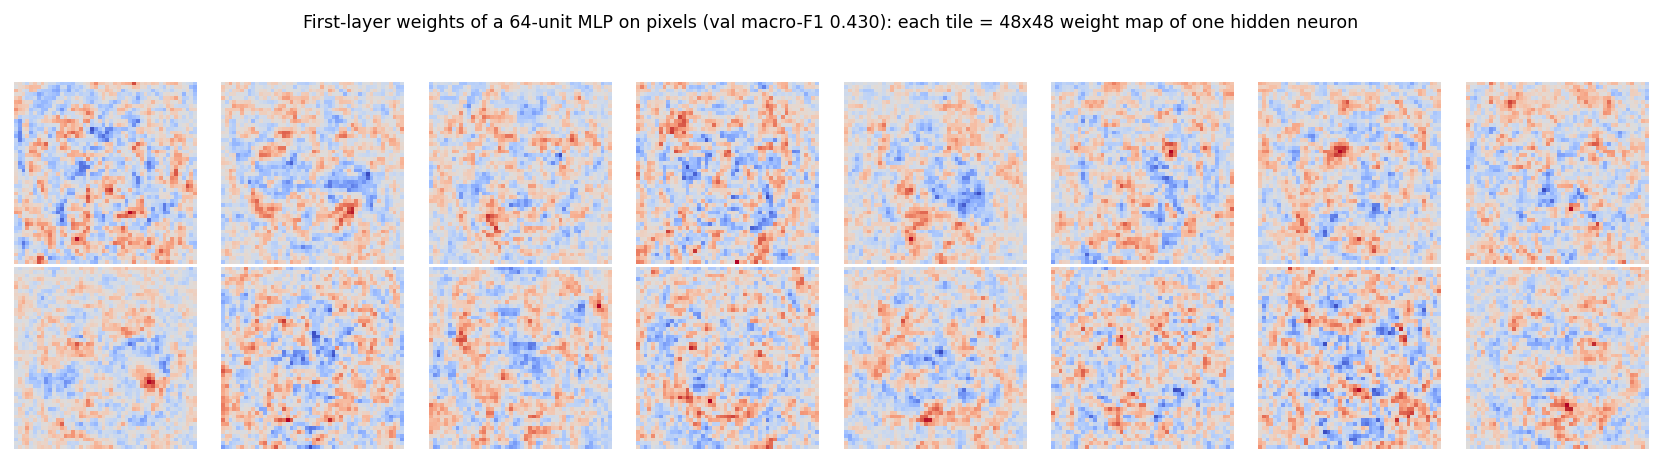

In [23]:
# (a) learning curve: how much does the amount of training data matter?
fr = (0.1, 0.25, 0.5, 0.75, 1.0)
lc = []
for f in fr:
    o = [fit(FINAL['prep'], s, FINAL['flip'], frac=f, **FC) for s in (0, 1)]
    lc.append((f, float(np.mean([r['va_f1'] for r in o])), float(np.mean([r['tr_acc'] for r in o]))))
fig, ax = plt.subplots(figsize=(5.2, 3.2)); ax.plot([a * len(tr) * (2 if FINAL['flip'] else 1) for a, _, _ in lc], [b for _, b, _ in lc], 'o-', label='validation macro-F1')
ax.plot([a * len(tr) * (2 if FINAL['flip'] else 1) for a, _, _ in lc], [c for _, _, c in lc], 's--', label='train accuracy'); ax.set_xlabel('# training samples'); ax.legend(); ax.set_title('Learning curve (final configuration)')
plt.tight_layout(); savefig('learning_curve'); plt.show(); print([(f, round(b, 4), round(c, 3)) for f, b, c in lc])

# (b) what do first-layer neurons look like? small 1-hidden-layer MLP on per-image-standardised pixels
m_ = fit('img_std', 0, False, keep=True, hidden=(64,), dropout=0., epochs=40)
W = m_['model'][0].weight.detach().cpu().numpy().reshape(-1, 48, 48)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for a_, w in zip(ax.ravel(), W[:16]): a_.imshow(w, cmap='coolwarm', vmin=-abs(w).max(), vmax=abs(w).max()); a_.axis('off')
plt.suptitle(f'First-layer weights of a 64-unit MLP on pixels (val macro-F1 {m_["va_f1"]:.3f}): each tile = 48x48 weight map of one hidden neuron', y=1.02, fontsize=9)
plt.tight_layout(); savefig('first_layer_weights'); plt.show()

## 18. Summary of all experiments

132 training configurations were evaluated; 243 individual training runs; total training time 38 min


,stage,val_acc,val_f1
0,"1 baseline (raw pixels, 512-256)",0.4704,0.4325
1,2 + best preprocessing,0.5630,0.5315
2,3 + best architecture,0.5855,0.5484
3,4 + best activation,0.5855,0.5484
4,5 + regularisation,0.5887,0.5522
5,6 + optimiser/lr/batch/sched,0.5952,0.5602
6,"7 final (re-checked, 3 fresh seeds)",0.6074,0.5747


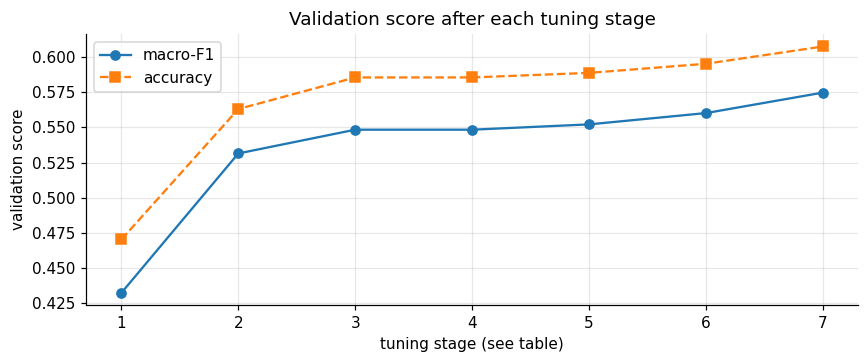

saved results/all_runs.csv, results/final_results.json and figs/*.png


In [24]:
all_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('_hist',)} for r in RUNS])
all_df['cfg'] = all_df['cfg'].apply(lambda c: json.dumps(c, default=str)); all_df['recall'] = all_df['recall'].apply(lambda r: json.dumps([round(x, 4) for x in r]))
all_df.to_csv('results/all_runs.csv', index=False)
print(len(all_df), 'training configurations were evaluated;', int(all_df.n_seeds.sum()), 'individual training runs; total training time %.0f min' % ((all_df['time'] * all_df['n_seeds']).sum() / 60))
stages = [('1 baseline (raw pixels, 512-256)', base), ('2 + best preprocessing', prep_recs_sorted[0]), ('3 + best architecture', max(allarch, key=lambda r: r['va_f1'])),
          ('4 + best activation', max(act_recs, key=lambda r: r['va_f1'])), ('5 + regularisation', reg_comb if reg_comb['va_f1'] >= reg_base['va_f1'] else reg_base),
          ('6 + optimiser/lr/batch/sched', opt_comb if opt_comb['va_f1'] >= opt_base['va_f1'] else opt_base), ('7 final (re-checked, 3 fresh seeds)', FINAL)]
progress = pd.DataFrame([dict(stage=s, val_acc=r['va_acc'], val_f1=r['va_f1']) for s, r in stages]); display(progress.round(4))
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.plot(range(len(progress)), progress.val_f1, 'o-', label='macro-F1'); ax.plot(range(len(progress)), progress.val_acc, 's--', label='accuracy')
ax.set_xticks(range(len(progress))); ax.set_xticklabels([s.split(' ')[0] for s in progress.stage]); ax.set_xlabel('tuning stage (see table)'); ax.set_ylabel('validation score'); ax.legend(); ax.set_title('Validation score after each tuning stage')
plt.tight_layout(); savefig('progress'); plt.show()
final_json = dict(student='Adel Ahmed Fathi Amer', student_id='224100177', clean=CLEAN_INFO, split=dict(train=len(tr), val=len(va), test=len(te)),
                  final_prep=FINAL['prep'], final_flip=bool(FINAL['flip']), final_cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in FC.items()},
                  n_params=finals[0]['n_params'], seed_test_acc=[a for a, _ in seed_res], seed_test_f1=[f for _, f in seed_res],
                  ens_test_acc=ens_acc, ens_test_f1=ens_f1, majority_test_acc=float(np.mean(yte_np == np.bincount(yte_np).argmax())),
                  val_acc=float(np.mean([f['va_acc'] for f in finals])), val_f1=float(np.mean([f['va_f1'] for f in finals])),
                  report=classification_report(yte_np, pred, target_names=NAMES, output_dict=True), confusion=cm.tolist(), names=NAMES,
                  progress=progress.to_dict('records'), learning_curve=[dict(frac=a, val_f1=b, tr_acc=c) for a, b, c in lc],
                  sklearn=sk_rows, best_prep=BEST_PREP, best_pix=BEST_PIX, best_arch=list(BEST_ARCH), conf_correct=float(conf[pred == yte_np].mean()), conf_wrong=float(conf[pred != yte_np].mean()),
                  top_confusions=[[int(c), a, b] for c, a, b in pairs], imb_recall={k: r['recall'] for k, r in imb_recs.items()},
                  adopted=dict(reg=reg_adopt, opt=opt_adopt, flip=bool(USE_FLIP), imbalance=best_imb[0]))
json.dump(final_json, open('results/final_results.json', 'w'), indent=1, default=str)
print('saved results/all_runs.csv, results/final_results.json and figs/*.png')

## 19. Conclusions
* **Final model:** HOG + LBP features (standardised) -> MLP 1024-512 (GELU, batch-norm, dropout 0.1, label smoothing 0.1, AdamW lr 2.9e-3, wd 2e-3, batch 256, cosine schedule, early stopping), trained on the training set plus horizontally flipped copies. 2.7 M parameters.
* **Test results (untouched until the end):** single MLPs 60.1 % +- 0.3 accuracy / 0.573 +- 0.004 macro-F1; the **5-MLP ensemble 62.2 % accuracy / 0.593 macro-F1** (majority-class baseline: 32.1 %; baseline MLP on raw pixels: 47.0 % / 0.433 on validation). Validation (60.5 % / 0.572) and test agree, so model selection did not over-fit the validation set.
* **What mattered, in order:** (1) the input representation (HOG/LBP vs pixels, ~+10 points macro-F1); (2) data hygiene - 30,232 of 59,099 images (51 %) were exact duplicates and 49 images carried conflicting labels, so without de-duplication the test score would be inflated by leakage; (3) augmentation and batch size (+1 point each); (4) architecture, activation, dropout, weight decay, imbalance handling (all within ~+-1 point).
* **Per class (test, ensemble):** Happy F1 0.80 (recall 0.82), Surprise 0.68, Sad 0.56, Angry 0.50, Fear 0.44. The most frequent errors are Fear -> Sad (191), Angry -> Sad (158), Sad -> Angry (128), Sad -> Happy (125) and Fear -> Angry (111): negative emotions share similar low-resolution facial configurations. Confidence is informative: it averages 0.71 on correct and 0.53 on wrong predictions.
* **Data-limited:** the learning curve is still rising (macro-F1 0.451 / 0.502 / 0.533 / 0.555 / 0.574 for 10 / 25 / 50 / 75 / 100 % of the training set) and training accuracy is ~100 %, so more (clean) data or stronger invariances would help more than more tuning.
* **Limits of an MLP:** it has no spatial inductive bias (the first-layer weight maps in Section 17b look like noisy, pixel-specific patterns rather than face parts), so it relies on hand-crafted HOG/LBP descriptors. Only exact duplicates were removed; near-duplicates and noisy web labels may remain, and 48x48 grayscale limits subtle expressions. Convolutional networks, which were not allowed here, would be the natural next step.